# 05a — Patient-cluster sensitivity

## Summary

Compare ordinary and patient-cluster confidence intervals on identical complete-case admissions in the refined primary and exploratory first-day-SOFA core models. The point estimate is shared; inference changes. Saved clinical execution results are displayed separately below. A new runtime execution defaults to current clinical data and stops if required access or configuration is missing.

<!-- Generated notebook input context -->

## Inputs and execution mode

New execution defaults to current clinical data. The input cell announces its mode before loading. Missing configuration, credentials or access stops execution without a synthetic fallback. Choose synthetic explicitly for artificial software checks, or local explicitly for a verified saved aggregate bundle. Existing stored runtime outputs retain their earlier origin labels; changing this policy does not rerun or revalidate them.

Stored-output evidence: [original clinical execution](../docs/NOTEBOOK_EXECUTION_VALIDATION.json) · [presentation refresh](../docs/NOTEBOOK_PRESENTATION_VALIDATION.json). · [current-mode execution](../docs/SUPPLEMENT_NOTEBOOK_EXECUTION_VALIDATION.json).

<!-- Generated saved clinical supplement: cluster/intro; edit scripts/render_supplement_notebook_summaries.py -->

## Saved clinical results

The tables and figures in this section display saved clinical execution results from [the public aggregate record](../docs/SURVIVAL_SENSITIVITY_RESULTS.json). They do not represent a new clinical rerun. The separately labeled execution section describes how to reproduce outputs. Any synthetic execution is explicitly labeled and is not a clinical MIMIC result.

<!-- Generated saved clinical supplement: cluster/cohort; edit scripts/render_supplement_notebook_summaries.py -->

### Table 1 — Saved admissions and patient dependence

| Measure | Count |
| --- | ---: |
| Admissions | 11,964 |
| In-hospital deaths | 1,692 |
| Patients | 9,157 |
| Patients with repeated admissions | 1,656 |
| Admissions contributed by repeat patients | 4,463 |

**Summary:** 11,964 admissions represent 9,157 patients; 1,656 patients contributed 4,463 admissions across repeated hospitalizations.

<!-- Generated saved clinical supplement: cluster/estimates; edit scripts/render_supplement_notebook_summaries.py -->

### Table 2 — Saved ordinary and patient-cluster Cox inference

| Model | HR | Ordinary 95% CI | Patient-cluster 95% CI | Ordinary p | Cluster p |
| --- | ---: | --- | --- | ---: | ---: |
| Primary age/sex/era | 0.732 | 0.592–0.904 | 0.593–0.902 | 0.00383 | 0.00346 |
| Exploratory first-day SOFA core | 0.833 | 0.673–1.030 | 0.665–1.042 | 0.09122 | 0.11019 |

**Summary:** Primary age/sex/era: HR 0.732 (95% CI 0.593–0.902); p=0.003455. 11,964 admissions, 1,692 deaths. The interval lies below 1. Exploratory SOFA core: HR 0.833 (95% CI 0.665–1.042); p=0.1102. 11,964 admissions, 1,692 deaths. The interval includes 1; this does not establish equivalence or absence of an association.

### Figure 1 — Ordinary and patient-cluster inference

![Figure 1 — Ordinary and patient-cluster inference](../assets/supplementary_cluster_forest.png)

**How to read**

- Gray circles show ordinary admission-level 95% intervals; blue squares show patient-cluster 95% intervals. Colors distinguish inference methods, not exposure groups. Each pair shares one fitted RAAS HR and the same complete cases; its vertical offset is only for readability.
- The dashed HR=1 line represents equal hazards. Patient clustering allows dependence among repeated admissions from one patient when estimating uncertainty; it does not fit a frailty model, remove confounding or change the exposure definition. A cluster interval can be wider or narrower.

**What the results show**

- The primary HR is 0.732, with patient-cluster CI 0.593–0.902. The interval lies below 1. The exploratory SOFA-core HR is 0.833, with cluster CI 0.665–1.042. The interval includes 1; this does not establish equivalence or absence of an association.

**Interpretation limits**

- Compare uncertainty methods within a model. The two covariate specifications are not a formal between-model test or evidence of causal treatment benefit; the SOFA timing limitation remains.

## Context & Methods

Keep the current exposure, outcome, age, sex, era strata, covariates and Efron ties. Fit unpenalized Cox models and sum Efron score residuals over all admissions of each patient, including across era strata. Form an HC0 sandwich covariance with asymptotic normal Wald intervals and p-values.

### Key assumptions
- Patients are independent clusters; admissions within a patient may be dependent. This does not fit a frailty or recurrent-event process model.
- No weights, delayed entry, or finite-cluster correction are used.
- The core model retains the published first-day-SOFA timing limitation.
- Tied event/censor times are handled deterministically; synthetic coefficients and covariance are checked against R `survival::coxph`.
- Current-data execution must reproduce the ordinary saved reference before returning a result.

## Data

Run from the repository root or `notebooks/` after `uv sync --locked`, using the repository Python 3.12 kernel. New execution defaults to `current` and uses the existing read-only BigQuery loader, a US dry run and the 200 MB cap. Configuration, authentication or permission failures stop with a reason and next step. Select `synthetic` explicitly for artificial software tests, or `local` explicitly to inspect a verified saved aggregate bundle without another query. Pseudonymous keys stay in memory; never print source rows.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO_ROOT / "scripts"))
import supplement_notebook_runtime as notebook_runtime
%matplotlib inline
plt.rcParams.update({"font.size": 10, "figure.dpi": 110})
import notebook_presentation as presentation

Matplotlib is building the font cache; this may take a moment.


## Runtime execution

The selected input origin is displayed once below, and again only if it changes. The default is current clinical data; configuration or access failure stops execution. Synthetic demonstrations and saved local aggregates require explicit selection. Figure 1 above remains the fixed published aggregate snapshot; stored runtime outputs retain their earlier execution labels.

In [2]:
# Current clinical data is the default. Other modes require explicit selection.
# Clear earlier results before loading; a failure must not redisplay a previous run.
import os, json
bundle = None
result = None
DATA_MODE = notebook_runtime.resolve_mode()  # current (default), local, synthetic
LOCAL_RESULT = REPO_ROOT / "reports/local_supplements/sensitivity_run02/aggregate_results.json"
BOOTSTRAP_REPLICATES = 1000 if DATA_MODE == "current" else 200

bundle = notebook_runtime.run_notebook_supplement(
    "cluster", repo=REPO_ROOT, mode=DATA_MODE, local_result=LOCAL_RESULT,
    bootstrap_replicates=BOOTSTRAP_REPLICATES)
result = bundle["results"]["cluster"]
presentation.display_input_context(bundle, mode=DATA_MODE)
# Retain only the aggregate execution bundle under the ignored run directory.
if os.environ.get("COPD_NOTEBOOK_RUN_DIR"):
    aggregate_output = Path(os.environ["COPD_NOTEBOOK_RUN_DIR"]) / "supplement_bundle.json"
    aggregate_output.parent.mkdir(parents=True, exist_ok=True)
    aggregate_output.write_text(json.dumps(bundle, indent=2, allow_nan=False) + "\n")

Input mode = current | CURRENT clinical data: existing read-only SELECT; US dry run and 200 MB cap. Access/configuration failure stops execution.


### Repeated admissions and ties

In [3]:
cohort_checks = pd.DataFrame([{k: m[k] for k in ["n", "events", "patients", "patients_with_multiple_admissions", "admissions_from_repeat_patients", "tied_event_sets_within_era"]} for m in result["models"].values()], index=list(result["models"]))
presentation.display_table("05a", "cohort", cohort_checks, " ".join(f"{name}: {m["n"]:,} admissions, {m["patients"]:,} patients, {m["patients_with_multiple_admissions"]:,} patients with repeated admissions, {m["tied_event_sets_within_era"]:,} tied event sets within era." for name, m in result["models"].items()), bundle=bundle)

,n,events,patients,patients_with_multiple_admissions,admissions_from_repeat_patients,tied_event_sets_within_era
primary_refined,11964,1692,9157,1656,4463,1
core,11964,1692,9157,1656,4463,1


### Estimates on the same admissions

In [4]:
presentation.display_table("05a", "models", presentation.supplement_models_frame(result), presentation.supplement_models_summary(result), bundle=bundle)

,Model,Admissions,Patients,RAAS HR,Ordinary 95% CI,Patient-cluster 95% CI,Ordinary p,Patient-cluster p
0,primary_refined,11964,9157,0.732,0.592–0.904,0.593–0.902,0.003832,0.003455
1,core,11964,9157,0.833,0.673–1.030,0.665–1.042,0.09122,0.1102


### Selected-execution figure

The following shared display call generates the figure number, title and numerical interpretation from this execution's aggregate result.

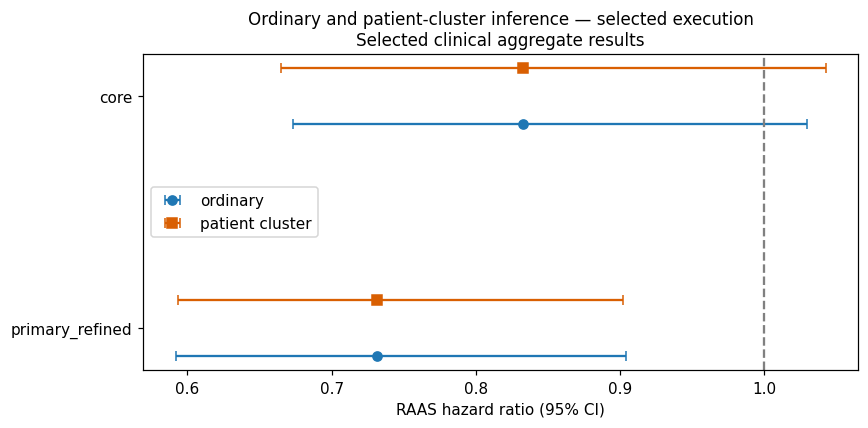

In [5]:
presentation.display_runtime_figure(bundle, "cluster")

## Takeaways

The estimate table and forest plot compare uncertainty methods, not different fitted exposure effects. Review the primary cluster interval alongside the ordinary interval regardless of significance. Changing the published main-analysis inference requires updating its provenance and independent verification together; this notebook does not overwrite them.

See [the supplement guide](../docs/SURVIVAL_SENSITIVITY_SUPPLEMENTS.md) for the execution commands, data handling, reference checks and limitations. Historical [execution](../docs/NOTEBOOK_EXECUTION_VALIDATION.json) and [presentation](../docs/NOTEBOOK_PRESENTATION_VALIDATION.json) evidence is kept separately from this input-policy source change. Publishing changed sources or new runtime outputs requires a matching reviewed validation record. Full local result bundles stay under ignored `reports/local_supplements/`.